In [2]:
import numpy as np
import kagglehub
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import HistGradientBoostingRegressor


from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from threadpoolctl import threadpool_limits

sns.set_theme(style="darkgrid")
plt.rcParams["figure.figsize"] = (9, 4)

/mnt/c/Users/mhallan/prog/ml/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Получаем файлы задачи с kaggle

In [3]:
# Download latest version
# path = kagglehub.competition_download("predicting-the-rating-of-board-games-2026")
path = Path(
    "/home/mhallan/.cache/kagglehub/competitions/predicting-the-rating-of-board-games-2026"
)

print("Path to competition files:", path)

Path to competition files: /home/mhallan/.cache/kagglehub/competitions/predicting-the-rating-of-board-games-2026


In [29]:
print("Файлы в папке:")
print(*os.listdir(path), sep=", ")

Файлы в папке:
train_data.csv, test_data.csv, sample_submition.csv


In [4]:
train_filename, test_filename, _ = os.listdir(path)

train_path = os.path.join(path, train_filename)
test_path = os.path.join(path, test_filename)

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

Преобразуем строчные данные в числа с плавающей запятой

In [5]:
target = "Rating Average"

for col in [target, "Complexity Average"]:
    train_df[col] = pd.to_numeric(
        train_df[col].astype("string").str.replace(",", ".", regex=False),
        errors="coerce",
    )

numeric_cols = (
    train_df.drop(["ID"], axis=1).select_dtypes(include=[np.number]).columns.tolist()
)
print(f"Числовые признаки: {', '.join(numeric_cols)}")

Числовые признаки: Year Published, Min Players, Max Players, Play Time, Min Age, Users Rated, Rating Average, BGG Rank, Complexity Average, Owned Users


In [6]:
df = train_df.copy()

### Files

* **`train_data.csv`** — набор данных с ответами для обучения и тестирования
* **`test.csv`** — набор данных без ответов, для которого необходимо получить ответы и загрузить на платформу
* **`sample_submission.csv`** — пример файла с ответами (ответы сгенерированы случайным образом)

### Columns

| Название | Описание |
| :--- | :--- |
| **ID** | Идентификатор настольной игры |
| **Name** | Имя |
| **Year Published** | Год публикации |
| **Min Players** | Рекомендуемое минимальное количество игроков |
| **Max Players** | Рекомендуемое максимальное количество игроков |
| **Play Time** | Время игры |
| **Min Age** | Рекомендуемый минимальный возраст игроков |
| **Users Rated** | Количество пользователей, оценивших игру |
| **Rating Average** | Средний рейтинг, полученный игрой (целевая переменная) |
| **BGG Rank** | Рейтинг от BGG |
| **Complexity Average** | Среднее значение сложности игры |
| **Owned Users** | Количество зарегистрированных BGG владельцев игры |
| **Mechanics** | Механика, используемая в игре |
| **Domains** | Домены настольных игр, которым принадлежит игра |

## Преобразуем таблицу в местах, где есть явные пропуски

In [7]:
# Настоящие пропуски: NaN, None, pd.NA
df.isna().sum()

ID                      10
Name                     0
Year Published           1
Min Players              0
Max Players              0
Play Time                0
Min Age                  0
Users Rated              0
Rating Average           0
BGG Rank                 0
Complexity Average       0
Owned Users             17
Mechanics             1200
Domains               7649
dtype: int64

In [8]:
# Проверка на infinite значения
np.isinf(df[numeric_cols]).sum()

Year Published        0
Min Players           0
Max Players           0
Play Time             0
Min Age               0
Users Rated           0
Rating Average        0
BGG Rank              0
Complexity Average    0
Owned Users           0
dtype: Int64

In [9]:
# Проверка на пропуски в столбце "Year Published"
df.loc[df["Year Published"].isna() | df["Year Published"] <= 0][
    "Year Published"
].value_counts().sum()

np.int64(143)

In [10]:
# Ячейки, содержащие ровно текст "nan" (без пробелов по краям)
text_nan = df.apply(
    lambda col: col.astype("string").str.strip().str.lower().eq("nan")
).fillna(False)
print("Количество ячеек с текстом 'nan':", text_nan.sum().sum())

Количество ячеек с текстом 'nan': 0


In [11]:
df.dropna(subset=["ID"], inplace=True)
df["ID"] = df["ID"].astype(int)

df["Year Published"] = df["Year Published"].astype(int)

df["Owned Users"] = df["Owned Users"].fillna(0)
df["Owned Users"] = df["Owned Users"].astype(int)

print("Выкинуто", len(train_df) - len(df), "строк с пустым ID")
# df = df.set_index('ID')

Выкинуто 10 строк с пустым ID


In [12]:
matching_indices = df[df.duplicated()].index
print(f"Индексы полных дубликатов: {list(matching_indices)}")

Индексы полных дубликатов: []


## Применим multi-hot coding для признаков Mechanics и Domains

In [13]:
df.isna().sum().loc[lambda x: x > 0]

Mechanics    1190
Domains      7639
dtype: int64

In [14]:
df["Mechanics"] = df["Mechanics"].str.split(", ")
df["Domains"] = df["Domains"].str.split(", ")

In [15]:
print(
    f"Новых признаков от механик в смысле multi-hot coding: {df.explode('Mechanics')['Mechanics'].nunique()}"
)
print(
    f"Новых признаков от доменов в смысле multi-hot coding: {df.explode('Domains')['Domains'].nunique()}"
)
# print(*set(df.explode('Mechanics')['Mechanics'].tolist()), sep='\n')

Новых признаков от механик в смысле multi-hot coding: 182
Новых признаков от доменов в смысле multi-hot coding: 8


In [16]:
# Добавим новые признаки в виде multi-hot encoding для механик и доменов
def encode_tags(df, column):
    exploded = df.explode(column)

    return (
        pd.get_dummies(exploded[column], dtype=int)
        .groupby(level=0)
        .max()
        .add_prefix(f"{column}_")
    )


domains_dummies = encode_tags(df, "Domains")
mechanics_dummies = encode_tags(df, "Mechanics")

In [17]:
df = pd.concat([df, domains_dummies, mechanics_dummies], axis=1)
df.drop(columns=["Mechanics", "Domains", "ID"], inplace=True)

In [18]:
df.head()

,Name,Year Published,Min Players,Max Players,Play Time,Min Age,Users Rated,Rating Average,BGG Rank,Complexity Average,...,Mechanics_Turn Order: Role Order,Mechanics_Turn Order: Stat-Based,Mechanics_Variable Phase Order,Mechanics_Variable Player Powers,Mechanics_Variable Set-up,Mechanics_Victory Points as a Resource,Mechanics_Voting,Mechanics_Worker Placement,Mechanics_Worker Placement with Dice Workers,Mechanics_Zone of Control
0,Gloomhaven,2017,1,4,120,14,42055,8.79,1,3.86,...,0,0,0,1,0,0,0,0,0,0
1,Brass: Birmingham,2018,2,4,120,14,19217,8.66,3,3.91,...,0,1,0,0,1,0,0,0,0,0
2,Terraforming Mars,2016,1,5,120,12,64864,8.43,4,3.24,...,0,0,0,1,0,0,0,0,0,0
3,Twilight Imperium: Fourth Edition,2017,3,6,480,14,13468,8.7,5,4.22,...,0,0,1,1,0,0,1,0,0,0
4,Gloomhaven: Jaws of the Lion,2020,1,4,120,14,8392,8.87,6,3.55,...,0,0,0,1,0,0,0,0,0,0


In [19]:
df.isna().sum().sum()

np.int64(0)

## Графики

Распределение рейтинга в обучающей выборке:

In [20]:
eda = df.copy()

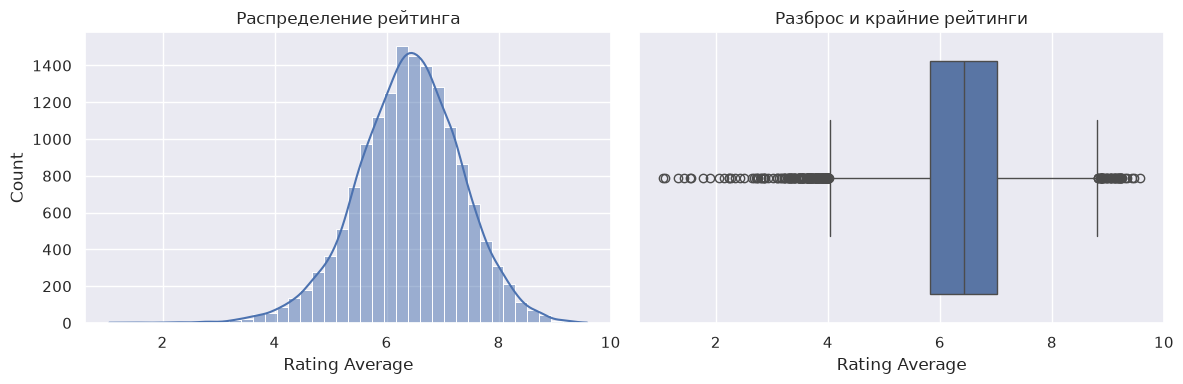

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(eda[target], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Распределение рейтинга")

sns.boxplot(x=eda[target], ax=axes[1])
axes[1].set_title("Разброс и крайние рейтинги")

plt.tight_layout()
plt.show()

Зависимость рейтинга от остальных признаков

In [22]:
print(*[col for col in numeric_cols if col != target])

Year Published Min Players Max Players Play Time Min Age Users Rated BGG Rank Complexity Average Owned Users


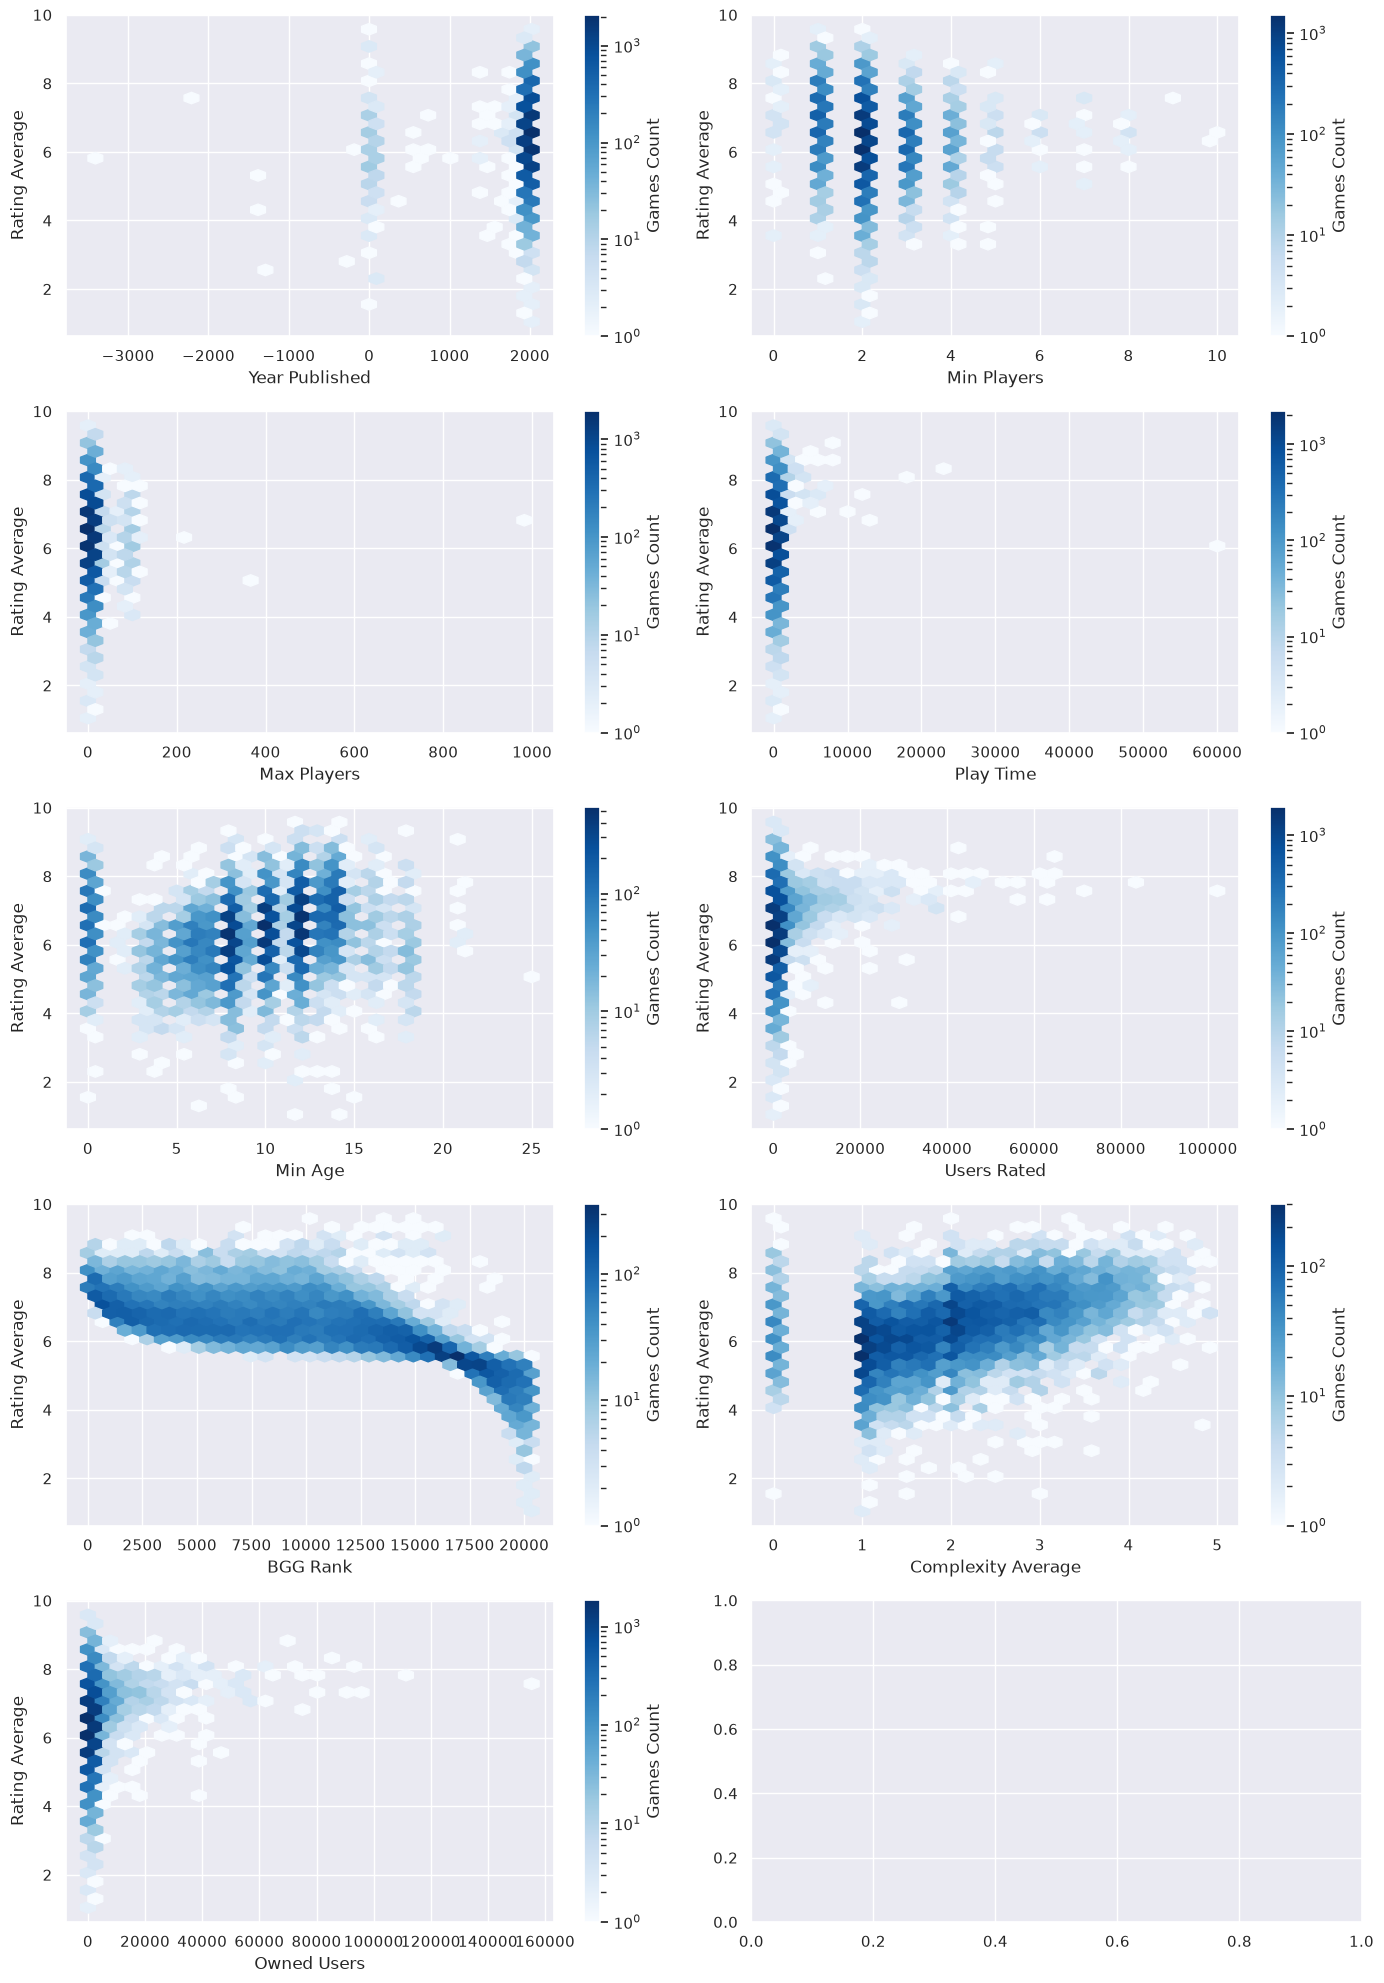

In [23]:
ncols = 2
plot_cols = [col for col in numeric_cols if col != target]

# log_cols = {
#     "Max Players",
#     "Play Time",
#     "Users Rated",
#     "Owned Users",
# }
nrows = (len(plot_cols) + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(14, 4 * nrows),
    squeeze=False,
)

for ax, col in zip(axes.flat, plot_cols):
    x = eda[col]
    y = eda[target]
    valid = x.notna() & y.notna()
    label = col

    # if col in log_cols:
    #     x = np.log1p(x.where(x >= 0))
    #     label = f"log1p({col})"

    plot = ax.hexbin(
        x[valid],
        y[valid],
        gridsize=30,
        mincnt=1,
        bins="log",
        cmap="Blues",
    )

    ax.set(xlabel=label, ylabel=target)
    fig.colorbar(plot, ax=ax, label="Games Count")

# Убираем незаполненную панель, если число признаков нечётное
# for ax in axes.flat[len(numeric_cols):]:
#     ax.set_visible(False)

plt.tight_layout()
plt.show()

Видно, что претенденты на изменения масштаба - `Owned Users`, `BGG Rank`,
`Users Rated`, `Playtime`

А также выбросы в виде записей, у которых `Year Published` <= 1500

Немного записей-выбросов в признаке `Max Players`

In [24]:
df[df["Year Published"] <= -2000]

,Name,Year Published,Min Players,Max Players,Play Time,Min Age,Users Rated,Rating Average,BGG Rank,Complexity Average,...,Mechanics_Turn Order: Role Order,Mechanics_Turn Order: Stat-Based,Mechanics_Variable Phase Order,Mechanics_Variable Player Powers,Mechanics_Variable Set-up,Mechanics_Victory Points as a Resource,Mechanics_Voting,Mechanics_Worker Placement,Mechanics_Worker Placement with Dice Workers,Mechanics_Zone of Control
123,Go,-2200,2,2,180,8,14843,7.64,173,4.0,...,0,0,0,0,0,0,0,0,0,0
6088,Senet,-3500,2,2,30,6,664,5.82,8176,1.48,...,0,0,0,0,0,0,0,0,0,0


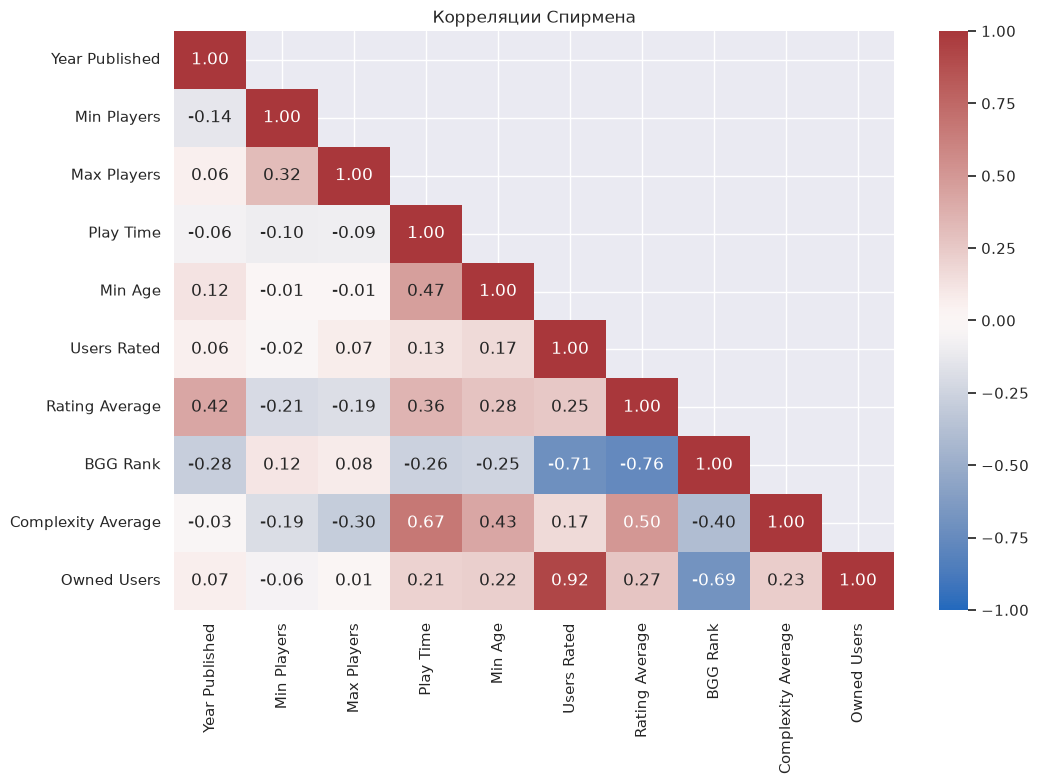

In [25]:
corr = eda[numeric_cols].corr(method="spearman")

plt.figure(figsize=(11, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    mask=np.triu(np.ones_like(corr, dtype=bool), k=1),
)
plt.title("Корреляции Спирмена")
plt.tight_layout()
plt.show()

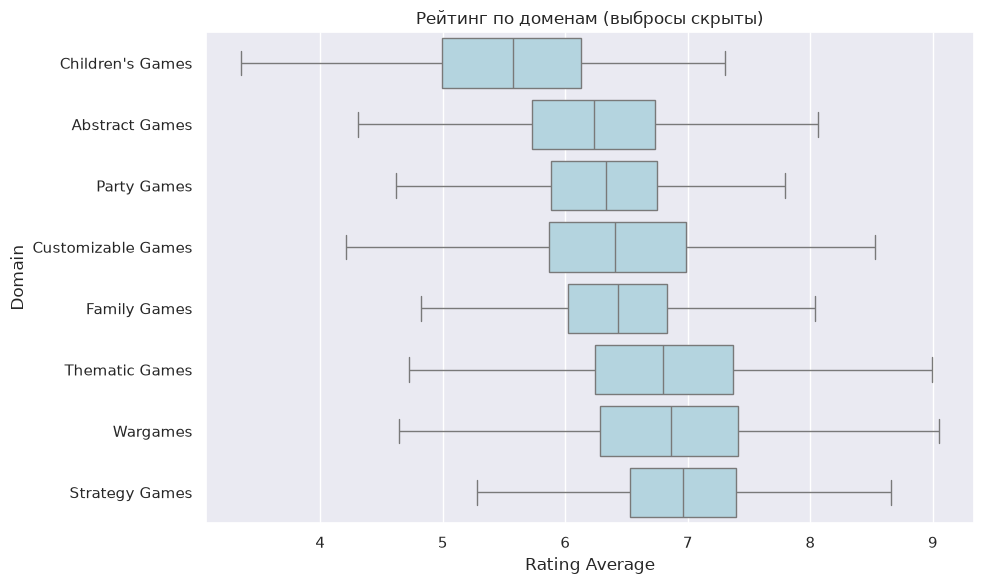

In [26]:
domain_data = (
    domains_dummies.rename(columns=lambda col: col.removeprefix("Domains_"))
    .join(eda[target])
    .melt(id_vars=target, var_name="Domain", value_name="present")
    .query("present == 1")
)

order = domain_data.groupby("Domain")[target].median().sort_values().index

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=domain_data,
    x=target,
    y="Domain",
    order=order,
    color="lightblue",
    showfliers=False,
)
plt.title("Рейтинг по доменам (выбросы скрыты)")
plt.tight_layout()
plt.show()

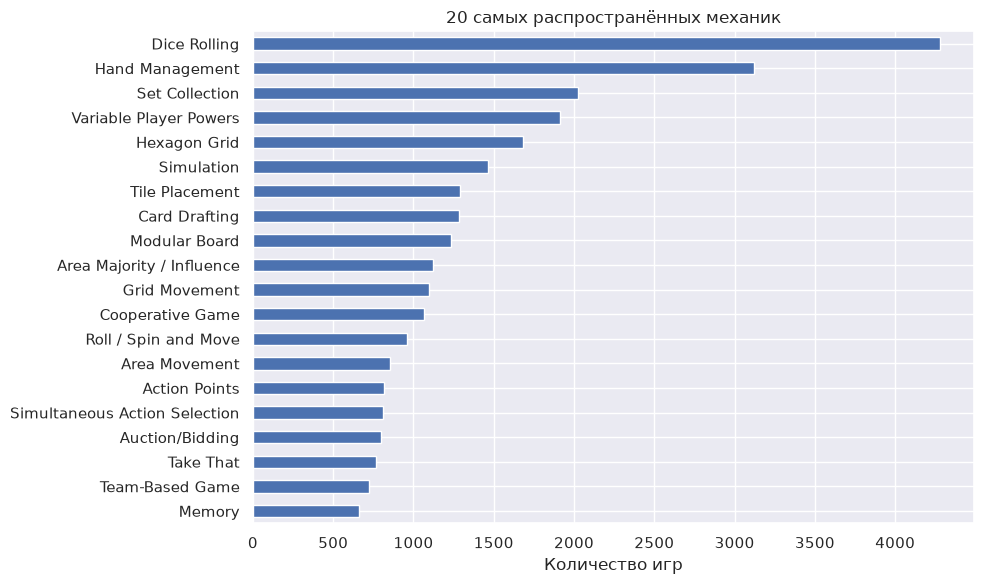

Механик, встречающихся менее чем у 10 игр: 33


In [27]:
counts = mechanics_dummies.sum()
counts.index = counts.index.str.replace("Mechanics_", "", regex=False)

popular_mechanics = counts.nlargest(20).sort_values()
popular_mechanics.plot.barh(figsize=(10, 6))

plt.xlabel("Количество игр")
plt.title("20 самых распространённых механик")
plt.tight_layout()
plt.show()

print("Механик, встречающихся менее чем у 10 игр:", (counts < 10).sum())

In [28]:
mechanics_list = popular_mechanics.index.tolist()
print("15 самых распространённых механик:", *mechanics_list, sep="\n")

15 самых распространённых механик:
Memory
Team-Based Game
Take That
Auction/Bidding
Simultaneous Action Selection
Action Points
Area Movement
Roll / Spin and Move
Cooperative Game
Grid Movement
Area Majority / Influence
Modular Board
Card Drafting
Tile Placement
Simulation
Hexagon Grid
Variable Player Powers
Set Collection
Hand Management
Dice Rolling


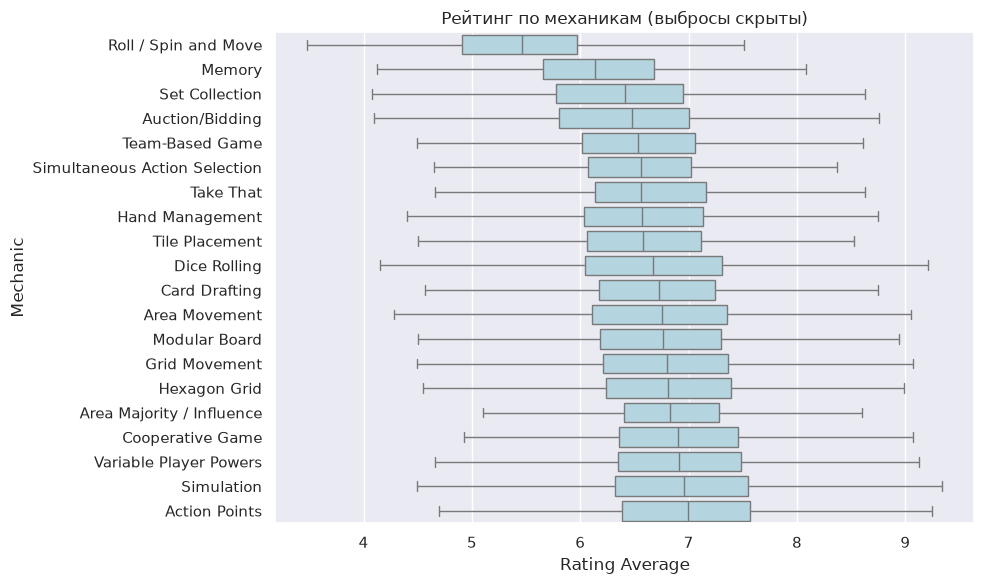

In [29]:
mechanics_list = ["Mechanics_" + m for m in mechanics_list]

mechanics_data = (
    mechanics_dummies[mechanics_list]
    .rename(columns=lambda col: col.removeprefix("Mechanics_"))
    .join(eda[target])
    .melt(id_vars=target, var_name="Mechanic", value_name="present")
    .query("present == 1")
)

order = mechanics_data.groupby("Mechanic")[target].median().sort_values().index

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=mechanics_data,
    x=target,
    y="Mechanic",
    order=order,
    color="lightblue",
    showfliers=False,
)
plt.title("Рейтинг по механикам (выбросы скрыты)")
plt.tight_layout()
plt.show()

In [65]:
target = "Rating Average"

numbers = [
    "Year Published",
    "Min Players",
    "Max Players",
    "Play Time",
    "Min Age",
    "Users Rated",
    "Owned Users",
    "Complexity Average",
    "BGG Rank",
]

mechanics_cols = mechanics_dummies.columns.tolist()
domains_cols = domains_dummies.columns.tolist()

data = df.copy()
# В EDA пропуски Owned Users были заменены нулями; восстанавливаем исходные значения.
data["Owned Users"] = train_df.loc[data.index, "Owned Users"]
test_data = pd.read_csv(Path(path) / "test_data.csv")

# Добавляем мульт хот кодированные признаки к тестовой выборке
for column, columns in [
    ("Mechanics", mechanics_cols),
    ("Domains", domains_cols),
]:
    test_data[column] = test_data[column].str.split(", ")
    encoded = encode_tags(test_data, column)

    # Одинаковые столбцы и порядок с обучающей таблицей.
    encoded = encoded.reindex(columns=columns, fill_value=0)
    test_data = pd.concat([test_data, encoded], axis=1)

test_data = test_data.drop(columns=["Mechanics", "Domains", "ID"])

ANCIENT_YEAR = 1500
POSITIVE_COLS = ("Min Players", "Max Players", "Play Time", "Min Age", "BGG Rank")
NONNEGATIVE_COLS = ("Users Rated", "Owned Users")

for frame in (data, test_data):
    for col in numbers:
        frame[col] = pd.to_numeric(
            frame[col].astype("string").str.replace(",", ".", regex=False),
            errors="coerce",
        ).astype(float)
    frame[numbers] = frame[numbers].replace([np.inf, -np.inf], np.nan)
    frame["Year Published"] = frame["Year Published"].replace(0, np.nan)
    for col in POSITIVE_COLS:
        frame[col] = frame[col].where(frame[col] > 0)
    for col in NONNEGATIVE_COLS:
        frame[col] = frame[col].where(frame[col] >= 0)
    frame["Complexity Average"] = frame["Complexity Average"].where(
        frame["Complexity Average"].between(1, 5)
    )
    invalid_players = frame["Min Players"] > frame["Max Players"]
    frame.loc[invalid_players, ["Min Players", "Max Players"]] = np.nan
    frame["year_pre1500"] = frame["Year Published"].lt(ANCIENT_YEAR).astype(int)

# Обучение через пайплайн

In [77]:
from sklearn.preprocessing import FunctionTransformer

feature_cols = numbers + mechanics_cols + domains_cols + ["year_pre1500"]

X = data[feature_cols].copy()
y = data[target].copy()

X_test = test_data[feature_cols].copy()

MIN_TAG_COUNT = 10
CLIP_TAIL = 0.005
POLY_DEGREE = 3
RIDGE_ALPHA = 1.0
RANDOM_STATE = 231
LOG_COLS = ("Max Players", "Play Time", "Users Rated", "Owned Users")
CLIP_COLS = ("Year Published", "Max Players", "Play Time")
FLAGS = ["year_pre1500"]

In [78]:
class QuantileClipper(TransformerMixin, BaseEstimator):
    """Отрезаем значения признаков по квантилям, чтобы уменьшить влияние выбросов."""

    def __init__(self, columns=CLIP_COLS, alpha=CLIP_TAIL, enabled=False):
        self.columns = columns
        self.alpha = alpha
        self.enabled = enabled

    def fit(self, X, y=None):
        if self.enabled:
            self.lower_ = X[list(self.columns)].quantile(self.alpha)
            self.upper_ = X[list(self.columns)].quantile(1 - self.alpha)
        return self

    def transform(self, X):
        X = X.copy()
        if self.enabled:
            X[list(self.columns)] = X[list(self.columns)].clip(
                self.lower_, self.upper_, axis=1
            )
        return X


class RareTags(TransformerMixin, BaseEstimator):
    """Отрезаем редкие теги (механики и домены), оставляя только те, что встречаются хотя бы min_count раз."""

    def __init__(self, min_count=MIN_TAG_COUNT):
        self.min_count = min_count

    def fit(self, X, y=None):
        self.columns_ = X.columns[X.sum() >= self.min_count].tolist()
        return self

    def transform(self, X):
        return X.loc[:, self.columns_].to_numpy(dtype=float)


def log_numeric(X, log_cols=LOG_COLS):
    """Логарифмируем числовые признаки, чтобы уменьшить влияние выбросов и сделать распределение более нормальным."""
    X = X.copy()
    for col in log_cols:
        X[col] = np.log1p(X[col].astype(float))
    return X


log_step = FunctionTransformer(log_numeric, validate=False)

In [111]:
from sklearn.preprocessing import SplineTransformer

ridge_numeric = Pipeline([
    ("clip", QuantileClipper(columns=CLIP_COLS, enabled=True)),
    ("log", log_step),
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("poly", PolynomialFeatures(degree=POLY_DEGREE, include_bias=False)),
])

rank_spline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("spline", SplineTransformer(
        n_knots=5,
        degree=3,
        knots="quantile",
        include_bias=False,
    )),
])

ridge_pipeline = Pipeline([
    ("features", ColumnTransformer([
        ("num", ridge_numeric, numbers),
        ("mechanics", RareTags(), mechanics_cols),
        ("domains", "passthrough", domains_cols),
        ("flags", "passthrough", FLAGS),
        ("rank_spline", "drop", ["BGG Rank"]),
    ])),
    ("scale", StandardScaler()),
    ("model", Ridge(alpha=RIDGE_ALPHA)),
    
])

boost_pipeline = Pipeline(
    [
        (
            "features",
            ColumnTransformer(
                [
                    ("num", "passthrough", numbers),
                    ("mechanics", RareTags(), mechanics_cols),
                    ("domains", "passthrough", domains_cols),
                    ("flags", "passthrough", FLAGS),
                    ("rank_spline", "drop", ["BGG Rank"]),
                ]
            ),
        ),
        ("model", HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
    ]
)

In [80]:
normalize = lambda s: s.fillna("").str.strip().str.casefold()
train_names = set(normalize(data["Name"])) - {""}
test_names = normalize(test_data["Name"])

print("Совпадений названий с train:", test_names.isin(train_names).sum())
print("Всего строк test:", len(test_names))

Совпадений названий с train: 135
Всего строк test: 5086


Полиномиальная регрессия (степени 3)
| Компонент | Параметр | Значение |
|---|---|---|
| features | flags | drop |
| features → mechanics | min_count | 10 |
| features → num | log | FunctionTransformer(log_numeric) |
| features → num → poly | degree | 3 |
| model | alpha | 0.1 |
|features__num__impute | add_indicator |False
| **$R^2$** | — | **0.924** |

In [102]:
from sklearn.model_selection import KFold

search = GridSearchCV(
    ridge_pipeline,
    param_grid={
        "features__num__log": [log_step],
        "features__num__impute__add_indicator": [False],
        "features__flags": ["drop"],
        "features__num__poly__degree": [3],
        "features__mechanics__min_count": [10],
        "model__alpha": [0.1],
        "features__rank_spline": ["drop", rank_spline],
    },
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    error_score="raise",
)

search.fit(X, y)
print(search.best_params_)
print("CV RMSE:", -search.best_score_)
best_ridge = search.best_estimator_

from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    best_ridge, X, y,
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="r2",
    n_jobs=1,
)
print("CV R²:", scores.mean())

{'features__flags': 'drop', 'features__mechanics__min_count': 10, 'features__num__impute__add_indicator': False, 'features__num__log': FunctionTransformer(func=<function log_numeric at 0x7f4366875b20>), 'features__num__poly__degree': 3, 'features__rank_spline': Pipeline(steps=[('impute', SimpleImputer(strategy='median')),
                ('spline',
                 SplineTransformer(include_bias=False, knots='quantile'))]), 'model__alpha': 0.1}
CV RMSE: 0.2508011581731082
CV R²: 0.9281083244137488


In [ ]:
rank_options = ["drop"] + [
    clone(rank_spline).set_params(spline__n_knots=k)
    for k in (21, 50, 100)
]

spline_search = GridSearchCV(
    clone(best_ridge),
    param_grid={
        "features__rank_spline": rank_options,
        "model__alpha": [0.005, 0.01],
    },
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    error_score="raise",
)
spline_search.fit(X, y)

print(spline_search.best_params_)
print("CV RMSE:", -spline_search.best_score_)

{'features__rank_spline': Pipeline(steps=[('impute', SimpleImputer(strategy='median')),
                ('spline',
                 SplineTransformer(include_bias=False, knots='quantile',
                                   n_knots=21))]), 'model__alpha': 0.01}
CV RMSE: 0.24239820825824446


In [112]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    spline_search.best_estimator_, X, y,
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="r2",
    n_jobs=1,
)
print("CV R²:", scores.mean())

CV R²: 0.932163454427342


In [81]:
from itertools import combinations

candidates = ("Max Players", "Play Time", "Users Rated", "Owned Users")
subsets = [
    subset
    for size in range(len(candidates) + 1)
    for subset in combinations(candidates, size)
]

log_options = [
    "passthrough" if not subset else FunctionTransformer(
        log_numeric,
        validate=False,
        kw_args={"log_cols": subset},
    )
    for subset in subsets
]

log_search = GridSearchCV(
    clone(best_ridge),  # фиксирует найденные degree, alpha, min_count и flags
    {"features__num__log": log_options},
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    error_score="raise",
)
log_search.fit(X, y)

display(
    pd.DataFrame({
        "log_columns": [", ".join(s) or "без логарифма" for s in subsets],
        "CV_RMSE": -log_search.cv_results_["mean_test_score"],
    }).sort_values("CV_RMSE")
)

,log_columns,CV_RMSE
15,"Max Players, Play Time, Users Rated, Owned Users",0.257595
14,"Play Time, Users Rated, Owned Users",0.259091
13,"Max Players, Users Rated, Owned Users",0.260427
10,"Users Rated, Owned Users",0.261323
11,"Max Players, Play Time, Users Rated",0.274077
8,"Play Time, Users Rated",0.274926
6,"Max Players, Users Rated",0.277054
3,Users Rated,0.277487
7,"Max Players, Owned Users",0.329471
4,Owned Users,0.331847


Загрузка предсказаний

In [107]:
submission = pd.read_csv(Path(path) / "sample_submition.csv")
assert len(submission) == len(X_test)

submission["Rating Average"] = np.clip(spline_search.best_estimator_.predict(X_test), 0, 10)
first_col = submission.columns[0]
submission = submission.rename(columns={first_col: "ID"})
submission.to_csv("submission_polynomial.csv", index=False)


Финальная метрика

# Бустинг

| Компонент | Параметр | Значение |
|---|---|---|
| model | min_samples_leaf | 20 |
| model | max_leaf_nodes | 31 |
| model | max_iter | 300 |
| model | learning_rate | 0.1 |
| model | l2_regularization | 0.0 |
| features → rank_spline | steps | SimpleImputer(median) → SplineTransformer |
| features → rank_spline → spline | include_bias | False |
| features → rank_spline → spline | knots | 'quantile' |
| features → rank_spline → spline | n_knots | 21 |
| features → num | log | FunctionTransformer(log_numeric) |
| features → mechanics | min_count | 5 |
| features → flags | — | passthrough |
| features → domains | — | passthrough |
| **CV RMSE** | — | **0.2135** |

In [114]:
from sklearn.model_selection import RandomizedSearchCV

rank_options = ["drop"] + [
    clone(rank_spline).set_params(spline__n_knots=k)
    for k in (5, 21)
]

boost_search = RandomizedSearchCV(
    boost_pipeline,
    param_distributions={
        "features__num": ["passthrough", log_step],
        "features__mechanics__min_count": [5, 10],
        "features__domains": ["drop", "passthrough"],
        "features__flags": ["drop", "passthrough"],
        "features__rank_spline": rank_options,
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_iter": [300, 500],
        "model__max_leaf_nodes": [7, 15, 31],
        "model__min_samples_leaf": [20, 50, 100],
        "model__l2_regularization": [0.0, 1.0, 10.0],
    },
    n_iter=30,
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=1,
    error_score="raise",
    verbose=1,
)

boost_search.fit(X, y)
print(boost_search.best_params_)
print("CV RMSE:", -boost_search.best_score_)

best_boost = boost_search.best_estimator_

Fitting 5 folds for each of 30 candidates, totalling 150 fits
{'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 31, 'model__max_iter': 300, 'model__learning_rate': 0.1, 'model__l2_regularization': 0.0, 'features__rank_spline': Pipeline(steps=[('impute', SimpleImputer(strategy='median')),
                ('spline',
                 SplineTransformer(include_bias=False, knots='quantile',
                                   n_knots=21))]), 'features__num': FunctionTransformer(func=<function log_numeric at 0x7f4366875b20>), 'features__mechanics__min_count': 5, 'features__flags': 'passthrough', 'features__domains': 'passthrough'}
CV RMSE: 0.21345478654241457


In [115]:
scores = cross_val_score(
    best_boost, X, y,
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="r2",
    n_jobs=1,
)
print("CV R²:", scores.mean())

CV R²: 0.9479243644913314


In [ ]:
boost_search = GridSearchCV(
    boost_pipeline,
    param_grid={
        "features__rank_spline": ["drop", rank_spline],
    },
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    error_score="raise",
)

boost_search.fit(X, y)

for option, score in zip(
    boost_search.cv_results_["param_features__rank_spline"],
    -boost_search.cv_results_["mean_test_score"],
):
    print("без сплайна" if option == "drop" else "со сплайном",
          f"RMSE: {score:.6f}")

best_boost = boost_search.best_estimator_

In [116]:
submission = pd.read_csv(Path(path) / "sample_submition.csv")
assert len(submission) == len(X_test)

submission["Rating Average"] = np.clip(best_boost.predict(X_test), 0, 10)
first_col = submission.columns[0]
submission = submission.rename(columns={first_col: "ID"})
submission.to_csv("submission_boosting.csv", index=False)


LGMB

In [118]:
from lightgbm import LGBMRegressor
from sklearn.model_selection import cross_validate

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

safe_cols = [f"f{i}" for i in range(X.shape[1])]

X_lgb = X.copy()
X_lgb.columns = safe_cols

X_test_lgb = X_test.reindex(columns=X.columns).copy()
X_test_lgb.columns = safe_cols

for max_bin in (255, 511, 1023):
    model = LGBMRegressor(
        objective="regression",
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=15,
        min_child_samples=40,
        reg_lambda=1.0,
        max_bin=max_bin,
        verbosity=-1,
        n_jobs=4,
        random_state=RANDOM_STATE,
    )

    scores = cross_validate(
        model, X_lgb, y, cv=cv,
        scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"},
        n_jobs=1,
    )
    print(
        f"max_bin={max_bin}: "
        f"RMSE={-scores['test_rmse'].mean():.6f}, "
        f"R²={scores['test_r2'].mean():.6f}"
    )

max_bin=255: RMSE=0.216584, R²=0.946359
max_bin=511: RMSE=0.217067, R²=0.946128
max_bin=1023: RMSE=0.217164, R²=0.946073


In [119]:
from lightgbm import LGBMRegressor

lgb_pipeline = Pipeline([
    ("features", ColumnTransformer([
        ("num", "passthrough", numbers),
        ("mechanics", "passthrough", mechanics_cols),
        ("domains", "passthrough", domains_cols),
        ("flags", "passthrough", FLAGS),
        ("rank_spline", "drop", ["BGG Rank"]),
    ], sparse_threshold=0)),
    ("model", LGBMRegressor(
        objective="regression",
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=15,
        min_child_samples=40,
        reg_lambda=1.0,
        max_bin=255,
        verbosity=-1,
        n_jobs=4,
        random_state=RANDOM_STATE,
    )),
])

lgb_search = GridSearchCV(
    lgb_pipeline,
    param_grid={
        "features__mechanics": ["passthrough", RareTags(10)],
        "features__domains": ["drop", "passthrough"],
        "features__rank_spline": [
            "drop",
            clone(rank_spline).set_params(spline__n_knots=21),
        ],
    },
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    error_score="raise",
    verbose=1,
)

lgb_search.fit(X, y)
print(lgb_search.best_params_)
print("CV RMSE:", -lgb_search.best_score_)

best_lgb = lgb_search.best_estimator_

Fitting 5 folds for each of 8 candidates, totalling 40 fits
{'features__domains': 'passthrough', 'features__mechanics': 'passthrough', 'features__rank_spline': Pipeline(steps=[('impute', SimpleImputer(strategy='median')),
                ('spline',
                 SplineTransformer(include_bias=False, knots='quantile',
                                   n_knots=21))])}
CV RMSE: 0.21523353019712652


In [120]:
scores = cross_val_score(
    best_lgb, X, y,
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="r2",
    n_jobs=1,
)
print("CV R²:", scores.mean())

CV R²: 0.9470038044460329


In [121]:
model_search = GridSearchCV(
    clone(best_lgb),
    param_grid=[
        {
            "model__learning_rate": [0.03],
            "model__n_estimators": [800],
            "model__num_leaves": [15, 31, 47],
        },
        {
            "model__learning_rate": [0.05],
            "model__n_estimators": [500],
            "model__num_leaves": [7, 15, 31],
        },
        {
            "model__learning_rate": [0.10],
            "model__n_estimators": [250],
            "model__num_leaves": [7, 15, 31],
        },
    ],
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    error_score="raise",
    verbose=1,
)

model_search.fit(X, y)
print(model_search.best_params_)
print("CV RMSE:", -model_search.best_score_)
best_lgb = model_search.best_estimator_

Fitting 5 folds for each of 9 candidates, totalling 45 fits
{'model__learning_rate': 0.03, 'model__n_estimators': 800, 'model__num_leaves': 31}
CV RMSE: 0.21016208849186505


In [122]:
scores = cross_val_score(
    best_lgb, X, y,
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="r2",
    n_jobs=1,
)
print("CV R²:", scores.mean())

CV R²: 0.9494980042100917


In [ ]:
regularization_search = GridSearchCV(
    clone(best_lgb),
    param_grid={
        "model__min_child_samples": [20, 40, 80],
        "model__reg_lambda": [0.0, 1.0, 5.0],
    },
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    error_score="raise",
    verbose=1,
)

regularization_search.fit(X, y)
print(regularization_search.best_params_)
print("CV RMSE:", -regularization_search.best_score_)
best_lgb = regularization_search.best_estimator_

Fitting 5 folds for each of 9 candidates, totalling 45 fits
{'model__min_child_samples': 20, 'model__reg_lambda': 0.0}
CV RMSE: 0.2081974830913432


In [124]:
leaf_search = GridSearchCV(
    clone(best_lgb),
    param_grid={
        "model__num_leaves": [20, 31],
        "model__min_child_samples": [10, 20],
    },
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    error_score="raise",
    verbose=1,
)

leaf_search.fit(X, y)
print(leaf_search.best_params_)
print("CV RMSE:", -leaf_search.best_score_)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
{'model__min_child_samples': 10, 'model__num_leaves': 31}
CV RMSE: 0.20790209773845275


In [126]:
scores = cross_val_score(
    best_lgb, X, y,
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="r2",
    n_jobs=1,
)
print("CV R²:", scores.mean())

CV R²: 0.9504394227285134


In [127]:
iteration_search = GridSearchCV(
    clone(best_lgb),
    {"model__n_estimators": [800, 1200, 1600]},
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    error_score="raise",
)

iteration_search.fit(X, y)
print(iteration_search.best_params_)
print("CV RMSE:", -iteration_search.best_score_)

{'model__n_estimators': 1600}
CV RMSE: 0.207504374332833


In [128]:
scores = cross_val_score(
    best_lgb, X, y,
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="r2",
    n_jobs=1,
)
print("CV R²:", scores.mean())

KeyboardInterrupt: 

In [130]:
submission = pd.read_csv(Path(path) / "sample_submition.csv")
assert len(submission) == len(X_test)

submission["Rating Average"] = np.clip(best_boost.predict(X_test), 0, 10)
first_col = submission.columns[0]
submission = submission.rename(columns={first_col: "ID"})
submission.to_csv("submission_lgbm.csv", index=False)


Сохранение

In [125]:
import cloudpickle

checkpoint = Path("/mnt/c/Users/mhallan/prog/ml/kaggle/checkpoint.pkl")

names = (
    "X", "y", "X_test",
    "best_lgb", "best_boost", "best_ridge",
    "lgb_search", "model_search", "regularization_search", "leaf_search",
)
state = {name: globals()[name] for name in names if name in globals()}

with checkpoint.open("wb") as file:
    cloudpickle.dump(state, file)

print("Сохранено:", checkpoint, list(state))

Сохранено: /mnt/c/Users/mhallan/prog/ml/kaggle/checkpoint.pkl ['X', 'y', 'X_test', 'best_lgb', 'best_boost', 'best_ridge', 'lgb_search', 'model_search', 'regularization_search', 'leaf_search']


Загрузка

In [ ]:
checkpoint = Path("/mnt/c/Users/mhallan/prog/ml/kaggle/checkpoint.pkl")

with checkpoint.open("rb") as file:
    state = cloudpickle.load(file)

globals().update(state)
print("Восстановлено:", list(state))